In [1]:
#loading my dataset
import pandas as pd

df_2025 = pd.read_excel(r'C:\Users\HP\Downloads\BESTEMM25.xlsx')
df_2026 = pd.read_excel(r'C:\Users\HP\Downloads\BESTEMM26.xlsx', sheet_name = 'Raw data')

In [2]:
#Assigning same column name for year
df_2025['Conference Year'] = 2025
df_2026['Conference Year'] = 2026

In [3]:
#Standardizing columns in both years
df_2026 = df_2026.rename(columns={'Residence':'Region of Residence'})
df_2025 = df_2025.rename(columns={'Gender Identity':'Gender'})
df_2025 = df_2025.rename(columns={'Do you Identify as Black?': 'Identifies as Black'})
df_2025 = df_2025.rename(columns={'Primary Discipline' : 'Discipline'})
df_2025 = df_2025.rename(columns={'Please select your current career level. Please see options below:' : 'Career Level'})
df_2026 = df_2026.rename(columns={'Identifies as black' : 'Identifies as Black'})
df_2026 = df_2026.rename(columns={'Age' : 'Age Group'})

In [4]:
import numpy as np

#Standardizing the gender column of 2026 into man, woman and unspecified
# 1. Cleaning any whitespace/typographic issues in the 2026 binary columns first
df_2026['man gender'] = pd.to_numeric(df_2026['man gender'], errors='coerce').fillna(0)
df_2026['woman gender'] = pd.to_numeric(df_2026['woman gender'], errors='coerce').fillna(0)

# 2. Defining the conditions and matching labels
conditions = [
    (df_2026['man gender'] == 1) & (df_2026['woman gender'] == 0),
    (df_2026['woman gender'] == 1) & (df_2026['man gender'] == 0),
    (df_2026['man gender'] == 1) & (df_2026['woman gender'] == 1)  # Edge case: selected both
]

choices = ['man', 'woman', 'both/non-binary']

# 3. Creating the unified 'gender' column for 2026
df_2026['Gender'] = np.select(conditions, choices, default='unspecified')

In [5]:
columns_to_fill = ['Gender', 'Identifies as Black', 'Career Level', 'Discipline', 'Region of Residence', 'Age Group', 'Conference Year']


df_2025 = df_2025 [columns_to_fill].fillna("No response")
df_2026 = df_2026 [columns_to_fill].fillna("No response")

In [6]:
# List of shared categorical columns to clean up
shared_cols = ['Gender', 'Identifies as Black', 'Career Level', 'Discipline', 'Region of Residence', 'Age Group', 'Conference Year']

for col in shared_cols:
    # Standardize 2025 text
    df_2025[col] = df_2025[col].astype(str).str.strip().str.lower()
    # Standardize 2026 text
    df_2026[col] = df_2026[col].astype(str).str.strip().str.lower()

In [7]:
#1.Expanding 2026 acronyms

career_map = {'o':'other', 'p':'non-academic stemm professional', 'ns': 'no response', 
             'm': 'mid or late career academic faculty (over 5 years since first appointment)',
              'e': 'early-career academic faculty (5 years or less since first academic appointment)', 
              'r': 'research assistant or research associate',
             'undergraduate':'undergraduate',
             'graduate':'graduate'}

region_of_residence_map = {'nt':'northern territories (yt, nt, nu)', 
                           'wc':'western canada (bc)', 
                           'pr':'prairies (ab, sk, mb)',
                           'ecc':'east central canada (on, qc)',
                           'ac':'atlantic canada (ns, pei, nb, nl)',
                           'oc':'outside canada',
                           'pns':'no response'}

discipline_map = {'ns':'natural sciences (biology, chemistry, physics, earth sciences)',
                  'eng':'engineering',
                  'hms':'health and medical sciences',
                  'cs':'computer science, data science and mathematics',
                  'ss':'social sciences and education in stemm', 
                  'o':'other', 'p':'no response'}

# 2.Standardizing 2026 columns and applying text expansions
for col in ['Career Level', 'Region of Residence', 'Discipline']:
    df_2026[col] = df_2026[col].astype(str).str.strip().str.lower()

df_2026['Career Level'] = df_2026['Career Level'].map(career_map)
df_2026['Region of Residence'] = df_2026['Region of Residence'].map(region_of_residence_map)
df_2026['Discipline'] = df_2026['Discipline'].map(discipline_map)

In [8]:
# 1. Cleaning the text while ensuring space is intact
df_2025['Age_Group'] = df_2025['Age Group'].astype(str).str.strip().str.lower()
df_2026['Age_Group'] = df_2026['Age Group'].astype(str).str.strip().str.lower()

# 2. Defining the mapping dictionary for 2025
map_2025 = {
    'under 25': 'under 25',
    'over 50': '50+',
    '25-50' : '25-50',
    'prefer not to say': 'no response',
    'nan': 'no response'
}

# 3. Defining the mapping dictionary for 2026 (incorporating the conveners' rule for '25')
map_2026 = {
    '25': 'under 25',       
    '26+': '25-50',          
    '50+': '50+',           
    'dont_say': 'no response',
    'no response': 'no response',
    'nan': 'No response'
}

# 4. Applying the mapping to create a uniform 'age_group' column in both dataframes
df_2025['Age_Group'] = df_2025['Age_Group'].map(map_2025).fillna('No response')
df_2026['Age_Group'] = df_2026['Age_Group'].map(map_2026).fillna('No response')

df_2025.head(10)

,Gender,Identifies as Black,Career Level,Discipline,Region of Residence,Age Group,Conference Year,Age_Group
0,man,yes,undergraduate student,"computer science, data science & mathematics","prairies (ab, sk, mb)",under 25,2025,under 25
1,man,yes,postgraduate student or candidate (masters or ...,health & medical science,"prairies (ab, sk, mb)",25–50,2025,No response
2,woman,yes,postdoctoral trainee,"natural sciences (e.g., biology, chemistry, ph...","prairies (ab, sk, mb)",25–50,2025,No response
3,woman,no,other,social sciences & education in stemm,"prairies (ab, sk, mb)",25–50,2025,No response
4,woman,yes,undergraduate student,social sciences & education in stemm,"prairies (ab, sk, mb)",25–50,2025,No response
5,woman,yes,mid or late career academic faculty (over 5 ye...,"natural sciences (e.g., biology, chemistry, ph...","prairies (ab, sk, mb)",over 50,2025,50+
6,woman,yes,postgraduate student or candidate (masters or ...,"health & medical science, social sciences & ed...","prairies (ab, sk, mb)",under 25,2025,under 25
7,prefer to self-describe,no,postgraduate student or candidate (masters or ...,social sciences & education in stemm,"prairies (ab, sk, mb)",over 50,2025,50+
8,man,yes,postdoctoral trainee,"engineering & technology, health & medical sci...","east central canada (on, qc)",25–50,2025,No response
9,woman,yes,mid or late career academic faculty (over 5 ye...,"natural sciences (e.g., biology, chemistry, ph...","east central canada (on, qc)",over 50,2025,50+


In [9]:
df_2025.loc[df_2025['Age Group'].astype(str).str.contains('25') & df_2025['Age Group'].astype(str).str.contains('50'), 'Age_Group'] = '25-50'
df_2025.loc[df_2025['Age Group'].astype(str).str.contains('under', case=False), 'Age_Group'] = 'under 25'
df_2025.loc[df_2025['Age Group'].astype(str).str.contains('over|50', case=False) & ~df_2025['Age Group'].astype(str).str.contains('25'), 'Age_Group'] = '50+'

# Fill whatever is left over as no response
df_2025['Age_Group'] = df_2025['Age_Group'].fillna('no response')

# Checking the results immediately
print(df_2025['Age_Group'].value_counts())

Age_Group
25-50          58
under 25       15
50+             8
no response     1
Name: count, dtype: int64


In [10]:
df_2025.head(10)

,Gender,Identifies as Black,Career Level,Discipline,Region of Residence,Age Group,Conference Year,Age_Group
0,man,yes,undergraduate student,"computer science, data science & mathematics","prairies (ab, sk, mb)",under 25,2025,under 25
1,man,yes,postgraduate student or candidate (masters or ...,health & medical science,"prairies (ab, sk, mb)",25–50,2025,25-50
2,woman,yes,postdoctoral trainee,"natural sciences (e.g., biology, chemistry, ph...","prairies (ab, sk, mb)",25–50,2025,25-50
3,woman,no,other,social sciences & education in stemm,"prairies (ab, sk, mb)",25–50,2025,25-50
4,woman,yes,undergraduate student,social sciences & education in stemm,"prairies (ab, sk, mb)",25–50,2025,25-50
5,woman,yes,mid or late career academic faculty (over 5 ye...,"natural sciences (e.g., biology, chemistry, ph...","prairies (ab, sk, mb)",over 50,2025,50+
6,woman,yes,postgraduate student or candidate (masters or ...,"health & medical science, social sciences & ed...","prairies (ab, sk, mb)",under 25,2025,under 25
7,prefer to self-describe,no,postgraduate student or candidate (masters or ...,social sciences & education in stemm,"prairies (ab, sk, mb)",over 50,2025,50+
8,man,yes,postdoctoral trainee,"engineering & technology, health & medical sci...","east central canada (on, qc)",25–50,2025,25-50
9,woman,yes,mid or late career academic faculty (over 5 ye...,"natural sciences (e.g., biology, chemistry, ph...","east central canada (on, qc)",over 50,2025,50+


In [11]:
df_2025['Age_Group']

0     under 25
1        25-50
2        25-50
3        25-50
4        25-50
        ...   
77       25-50
78       25-50
79    under 25
80       25-50
81         50+
Name: Age_Group, Length: 82, dtype: object

In [12]:
# 1. Define the exact clean columns to keep for the final trend analysis
final_columns = [
    'Conference Year', 
    'Age_Group', 
    'Gender', 
    'Identifies as Black', 
    'Career Level', 
    'Discipline', 
    'Region of Residence'
]

# 2. Creating a subset for both tables so they have the exact same clean columns
df_2025_clean = df_2025[final_columns]
df_2026_clean = df_2026[final_columns]

# 3. Concatenating (union) the datasets vertically into a single master file
df_all = pd.concat([df_2025_clean, df_2026_clean], ignore_index=True)

# 4. Final Verification Check
print("--- SUCCESS! Combined Dataset Info ---")
print(f"Total Rows: {len(df_all)}")
print("\nRows per Conference Year:")
print(df_all['Conference Year'].value_counts())

--- SUCCESS! Combined Dataset Info ---
Total Rows: 245

Rows per Conference Year:
Conference Year
2026    163
2025     82
Name: count, dtype: int64


In [13]:
df_all

,Conference Year,Age_Group,Gender,Identifies as Black,Career Level,Discipline,Region of Residence
0,2025,under 25,man,yes,undergraduate student,"computer science, data science & mathematics","prairies (ab, sk, mb)"
1,2025,25-50,man,yes,postgraduate student or candidate (masters or ...,health & medical science,"prairies (ab, sk, mb)"
2,2025,25-50,woman,yes,postdoctoral trainee,"natural sciences (e.g., biology, chemistry, ph...","prairies (ab, sk, mb)"
3,2025,25-50,woman,no,other,social sciences & education in stemm,"prairies (ab, sk, mb)"
4,2025,25-50,woman,yes,undergraduate student,social sciences & education in stemm,"prairies (ab, sk, mb)"
...,...,...,...,...,...,...,...
240,2026,25-50,unspecified,yes,graduate,"natural sciences (biology, chemistry, physics,...","east central canada (on, qc)"
241,2026,50+,woman,yes,mid or late career academic faculty (over 5 ye...,"natural sciences (biology, chemistry, physics,...","east central canada (on, qc)"
242,2026,25-50,woman,yes,graduate,health and medical sciences,"east central canada (on, qc)"
243,2026,50+,man,yes,mid or late career academic faculty (over 5 ye...,health and medical sciences,"east central canada (on, qc)"


In [14]:
# 1. TOTAL SCALE (Total Attendee Volume & Percentage Growth)
print("=== 1. SCALE SHIFT ===")

# Count total rows for each year
scale_counts = df_all['Conference Year'].value_counts().sort_index()
count_2025 = scale_counts.iloc[0]
count_2026 = scale_counts.iloc[1]

# Calculate absolute and percentage growth
absolute_growth = count_2026 - count_2025
pct_growth = (absolute_growth / count_2025) * 100

print(f"Total Attendees in 2025 (Regional): {count_2025}")
print(f"Total Attendees in 2026 (National): {count_2026}")
print(f"Absolute Growth: +{absolute_growth} participants")
print(f"Growth Percentage: {pct_growth:.1f}% increase in volume\n")




=== 1. SCALE SHIFT ===
Total Attendees in 2025 (Regional): 82
Total Attendees in 2026 (National): 163
Absolute Growth: +81 participants
Growth Percentage: 98.8% increase in volume



In [15]:
#2. PROFILE MIX (Gender distribution)

print("=== 2. MIX SHIFT (GENDER) ===")

# Create a cross-tabulation showing percentages by year
gender_mix = pd.crosstab(df_all['Conference Year'], df_all['Gender'], normalize='index') * 100

# Print the table rounded to 1 decimal place
gender_mix.round(1)

=== 2. MIX SHIFT (GENDER) ===


Gender,man,prefer not to say,prefer to self-describe,unspecified,woman
Conference Year,,,,,
2025,32.9,1.2,1.2,0.0,64.6
2026,41.7,0.0,0.0,2.5,55.8


We can see that the 2025 Regional conference was heavily dominated by females, making up 64.6% of the participants while in 2026, the percentage of male participants increased significantly by 9%

In [16]:
#Other biographic mix shifts

print("\n--- Age Group Mix (%) ---")
age_mix = pd.crosstab(df_all['Conference Year'], df_all['Age_Group'], normalize='index') * 100
print(age_mix.round(1))

print("\n--- Black Identity Mix (%) ---")
black_mix = pd.crosstab(df_all['Conference Year'], df_all['Identifies as Black'], normalize='index') * 100
print(black_mix.round(1))

print("\n--- Discipline Mix (%) ---")
discipline_mix = pd.crosstab(df_all['Conference Year'], df_all['Discipline'], normalize='index') * 100
print(discipline_mix.round(1))



--- Age Group Mix (%) ---
Age_Group        25-50   50+  no response  under 25
Conference Year                                    
2025              70.7   9.8          1.2      18.3
2026              55.8  10.4          3.7      30.1

--- Black Identity Mix (%) ---
Identifies as Black    no  no response   yes
Conference Year                             
2025                  7.3          0.0  92.7
2026                 12.9          1.2  85.9

--- Discipline Mix (%) ---
Discipline       computer science, data science & mathematics  \
Conference Year                                                 
2025                                                      7.3   
2026                                                      0.0   

Discipline       computer science, data science & mathematics, health & medical science, natural sciences (e.g., biology, chemistry, physics, earth sciences)  \
Conference Year                                                                                        

Across both years, the 25-50 age group dominated the conference. Also, almost all participants from both the Regional and National conference (85.9% and 92.7%) identified as Blacks.
For the Discipline, the Regional conference had more participants from the Natural sciences while more specialists from the Social sciences and education in STEMM attended the National conference in 2026.

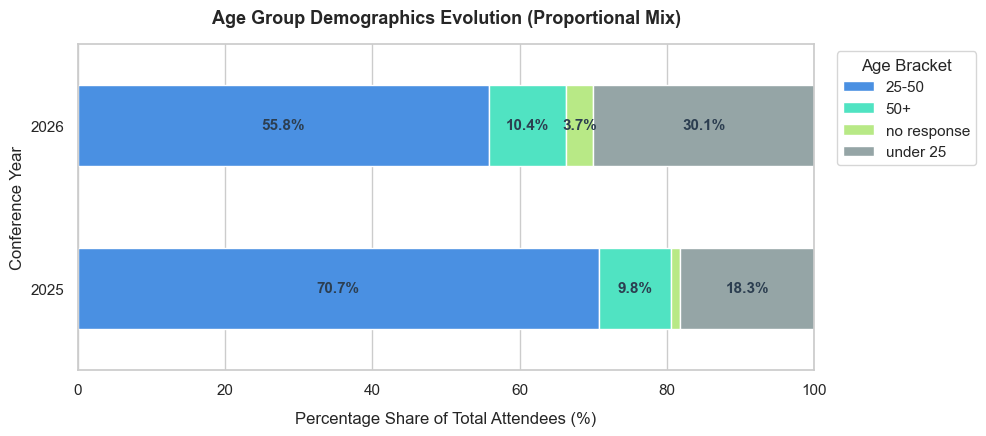

In [29]:
# VISUAL FOR AGE GROUP MIX

import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13})

fig, ax = plt.subplots(figsize=(10, 4.5))
age_mix.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=['#4a90e2', '#50e3c2', '#b8e986', '#95a5a6'],
    width=0.5)

# Overlaying individual percentage text markers inside the bars
for p in ax.patches:
    width = p.get_width()
    if width > 3: # Only display text if the segment segment is wide enough to read
        ax.text(
            p.get_x() + width/2, 
            p.get_y() + p.get_height()/2, 
            f'{width:.1f}%', 
            ha='center', va='center', color='#2c3e50', fontweight='bold'
        )

plt.title('Age Group Demographics Evolution (Proportional Mix)', pad=15, fontweight='bold')
plt.xlabel('Percentage Share of Total Attendees (%)', labelpad=10)
plt.ylabel('Conference Year')
plt.xlim(0, 100)
plt.legend(title='Age Bracket', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('Age Group Demographics Evolution (Proportional Mix).jpg', dpi=300, bbox_inches='tight')
plt.show()




In [19]:
#3. DISCIPLINE TREND MIX
# 1. Create a clean, standardized discipline column in your master dataset
df_all['Discipline_Clean'] = 'other / interdisciplinary'

# 2. Force group the text strings based on key phrases
df_all.loc[df_all['Discipline'].str.contains('natural science', na=False), 'Discipline_Clean'] = 'natural sciences'
df_all.loc[df_all['Discipline'].str.contains('engineering', na=False), 'Discipline_Clean'] = 'engineering'
df_all.loc[df_all['Discipline'].str.contains('computer science|data science|mathematics', na=False), 'Discipline_Clean'] = 'comp sci / data / math'
df_all.loc[df_all['Discipline'].str.contains('social science|education', na=False), 'Discipline_Clean'] = 'social sciences & education'
df_all.loc[df_all['Discipline'].str.contains('health|medical', na=False), 'Discipline_Clean'] = 'health & medical sciences'
df_all.loc[df_all['Discipline'].str.contains('no response|prefer not to say', na=False), 'Discipline_Clean'] = 'no response'

# 3. Generate a beautiful, clean cross-tabulation table
clean_discipline_mix = pd.crosstab(df_all['Conference Year'], df_all['Discipline_Clean'], normalize='index') * 100

print("=== CLEANED DISCIPLINE TREND MIX (%) ===")
clean_discipline_mix.round(1)


=== CLEANED DISCIPLINE TREND MIX (%) ===


Discipline_Clean,comp sci / data / math,engineering,health & medical sciences,natural sciences,no response,other / interdisciplinary,social sciences & education
Conference Year,,,,,,,
2025,8.5,6.1,42.7,24.4,1.2,3.7,13.4
2026,11.0,8.0,33.1,25.8,0.6,9.8,11.7


This cleaned output clearly shows that both the 2025 and 2026 conference had more participants from Health and Medical Sciences discipline , 
followed by Natural Sciences

In [20]:
# Career Level Distribution across years
print("\n--- Career Level Distribution (%) ---")
career_dist = pd.crosstab(df_all['Conference Year'], df_all['Career Level'], normalize='index') * 100
career_dist.round(1)


--- Career Level Distribution (%) ---


Career Level,early-career academic faculty (5 years or less since first academic appointment),early-career academic faculty (5 years or less since first faculty appointment),graduate,mid or late career academic faculty (over 5 years since first appointment),mid or late career academic faculty (over 5 years since first faculty appointment),no response,non-academic stemm professional,other,postdoctoral trainee,postgraduate student or candidate (masters or doctorate),research assistant or research associate,undergraduate,undergraduate student
Conference Year,,,,,,,,,,,,,
2025,0.0,6.1,0.0,0.0,8.5,0.0,18.3,7.3,18.3,23.2,3.7,0.0,14.6
2026,3.9,0.0,33.6,12.5,0.0,13.2,2.0,10.5,0.0,0.0,3.9,20.4,0.0


The regional conference recorded more Postgraduate students(23.2%) while most of the participants in the national conference were at Graduate Level (33.6%) who never attended the regional conerence. There was a decline in the attendance by early-career academic members in 2026, while there was an increase in the proportion of mid or late career academic faculty members

In [21]:
#4 GEOGRAPHIC REACH BROADENING 

# Generating the regional percentage breakdown by year
geo_reach = pd.crosstab(df_all['Conference Year'], df_all['Region of Residence'], normalize='index') * 100

geo_reach.round(1)


Region of Residence,"atlantic canada (ns, pei, nb, nl)","east central canada (on, qc)",no response,outside canada,"prairies (ab, sk, mb)",prefer not to say
Conference Year,,,,,,
2025,0.0,28.0,0.0,2.4,68.3,1.2
2026,5.0,75.2,0.6,1.2,18.0,0.0


The Regional Conference of 2025 was largely attended by residents of the Prairies (AB, SK, MB) while the National conference was largely dominated by residents of East Central Canada (ON, QC) accounting for 75% of the participants. Though it was noted that ECC accounted for the second largest resident attendee in 2025. 
The national conference successfully expanded its footprint and broke out of its local 2025 Prairies cluster. However, rather than drawing a perfectly equal nationwide distribution, the geographic reach shifted dramatically to East Central Canada, which accounted for 75% of all 2026 registrants. This suggests that while geographic reach broadened significantly past the Prairies, future national events may need targeted outreach to better engage the Atlantic, Western, and Northern regions.

In [22]:
# To create a quick summary column using aggregated data so that I can group easily for visualization
#1.Standardizing and grouping regions into requested buckets
df_all['Geo_Chart_Group'] = 'Rest of Canada/No response'
df_all.loc[df_all['Region of Residence'].str.contains('prairies', na=False), 'Geo_Chart_Group'] = 'Prairies'
df_all.loc[df_all['Region of Residence'].str.contains('ontario|quebec|east|central', na=False), 'Geo_Chart_Group'] = 'East Central Canada'

#2.Generating the percentage cross tabulation table
geo_chart_group = pd.crosstab(df_all['Conference Year'], df_all['Geo_Chart_Group'], normalize='index')*100

geo_chart_group.round(1)

Geo_Chart_Group,East Central Canada,Prairies,Rest of Canada/No response
Conference Year,,,
2025,28.0,68.3,3.7
2026,74.2,17.8,8.0


In [23]:
#To combine all small categories and clearly show the "Prairies" vs "East Central" vs "Rest of Canada" breakdown for easy comparism
df_all['Geo_Summary'] = df_all['Region of Residence']

# Checking what the 75% region is named exactly in your table (e.g., 'ontario' or 'quebec')
df_all.loc[df_all['Region of Residence'].str.contains('ontario|quebec|east|central', na=False), 'Geo_Summary'] = 'East Central Canada'

# Generating the final clean geographic table
geo_summary_table = pd.crosstab(df_all['Conference Year'], df_all['Geo_Summary'], normalize='index') * 100
geo_summary_table.round(1)

Geo_Summary,East Central Canada,"atlantic canada (ns, pei, nb, nl)",no response,outside canada,"prairies (ab, sk, mb)",prefer not to say
Conference Year,,,,,,
2025,28.0,0.0,0.0,2.4,68.3,1.2
2026,75.2,5.0,0.6,1.2,18.0,0.0


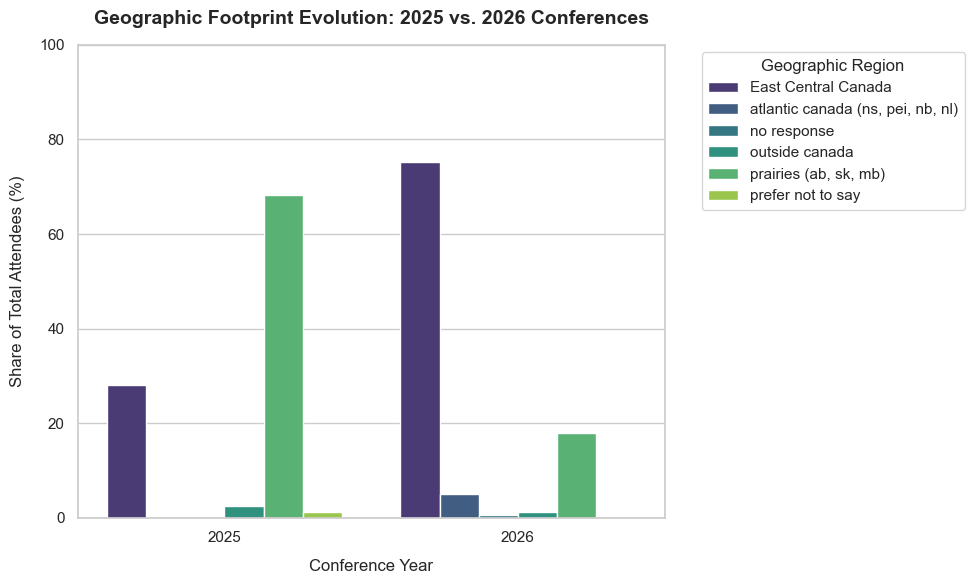

In [28]:
#Creating a grouped bar chart to visualize geographic reach
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculating the geographic summary percentages
geo_data = pd.crosstab(df_all['Conference Year'], df_all['Geo_Summary'], normalize='index') * 100

# 2. Reseting index to transform it into a long-form DataFrame for Seaborn plotting
geo_data_long = geo_data.reset_index().melt(id_vars='Conference Year', value_name='Percentage')

# 3. Setting up the plotting window layout
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 4. Creating the grouped bar chart
ax = sns.barplot(
    data=geo_data_long, 
    x='Conference Year', 
    y='Percentage', 
    hue='Geo_Summary', 
    palette='viridis'
)

# 5. Adding clear, professional titles and axis labels
plt.title('Geographic Footprint Evolution: 2025 vs. 2026 Conferences', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Conference Year', fontsize=12, labelpad=10)
plt.ylabel('Share of Total Attendees (%)', fontsize=12, labelpad=10)
plt.ylim(0, 100)

# 6. Adjusting the legend positioning so it doesn't block the bars
plt.legend(title='Geographic Region', bbox_to_anchor=(1.05, 1), loc='upper left')

# 7. Cleaning up layout margins and show the visual panel
plt.tight_layout()
plt.savefig('Geographic Footprint Evolution: 2025 vs. 2026 Conferences.jpg', dpi=300, bbox_inches='tight')
plt.show()


This chart re-emphasizes the fact that the 2 regions with more representation across both conferences are East central Canada (ECC) and Prairies 
though the proportion varies across the years

In [30]:
#5. BLACK-IDENTIFYING REGISTRANTS TREND 

#1.Now to check the black representation across the 2 conferences, first thing is to calculate raw counts to understand absolute scale growth
print('\n--Raw Counts (Absolute Numbers) ---')
black_counts = pd.crosstab(df_all['Conference Year'], df_all['Identifies as Black'])
black_counts

# 2. Percentages calculation to understand the share mix shift
print("\n--- Share Mix Breakdown (%) ---")
black_share = pd.crosstab(df_all['Conference Year'], df_all['Identifies as Black'], normalize='index') * 100
black_share.round(1)


--Raw Counts (Absolute Numbers) ---

--- Share Mix Breakdown (%) ---


Identifies as Black,no,no response,yes
Conference Year,,,
2025,7.3,0.0,92.7
2026,12.9,1.2,85.9


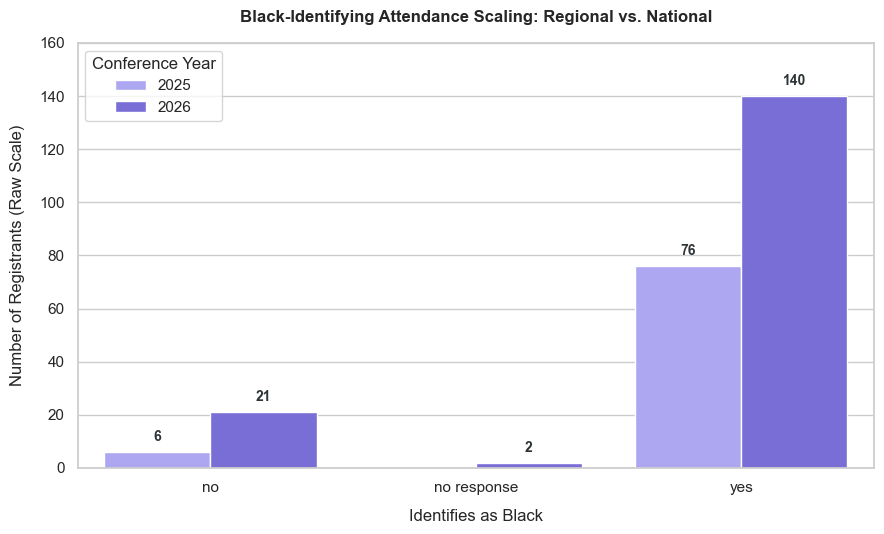

In [27]:
#Visualization for Black Identity
black_raw = pd.crosstab(df_all['Conference Year'], df_all['Identifies as Black']).reset_index()
black_long = black_raw.melt(id_vars='Conference Year', value_name='Attendee Count')

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(
    data=black_long,
    x='Identifies as Black',
    y='Attendee Count',
    hue='Conference Year',
    palette=['#a29bfe', '#6c5ce7'],
    ax=ax
)

# Append raw scalar digits on top of each block
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.text(
            p.get_x() + p.get_width()/2.,
            height + 3,
            f'{int(height)}',
            ha="center", va="bottom", fontsize=10, fontweight='bold', color='#2d3436'
        )

plt.title('Black-Identifying Attendance Scaling: Regional vs. National', pad=15, fontweight='bold')
plt.xlabel('Identifies as Black', labelpad=10)
plt.ylabel('Number of Registrants (Raw Scale)', labelpad=10)
plt.ylim(0, 160)
plt.legend(title='Conference Year')
plt.tight_layout()
plt.savefig('Black-Identifying Attendance Scaling: Regional vs. National.jpg', dpi=300, bbox_inches='tight')
plt.show()



Black-identifying registrants remained the overwhelming majority at both events. On a national stage, the absolute volume of Black participants nearly doubled, growing from 76 to 140 individuals. While their overall share of the attendee mix experienced a minor dilution shifting from 92.7% in 2025 to 85.9% in 2026, this was driven entirely by a small influx of non-Black attendees (growing from 7.3% to 12.9%). The data firmly establishes that the conference maintains a powerful, core Black-centered identity nationally.

Critical Flaws to Flag for the Society

Here are the core data quality issues to be noted:

1. Inconsistent Field Taxonomy (The Naming Trap)

• The Issue: The form layout changed though the data dictionary helped. For example, changing residence (provinces) to region_of_residence (broad territories)
• The Impact: Breaks multi-year programming scripts. It forces an analyst to do manual re-mapping in Python instead of generating instant automated charts.

2. Structural Column Splitting (One-Hot Encoding Mismatch)

• The Issue: The 2025 form collected gender as a clean text string drop-down, while 2026 split gender into completely separate binary check-box columns (man, woman).
• The Impact: Increases database bloat and introduces user submission errors. As seen in the earlier analysis, this setup created an edge case where users could choose both or leave both blank, resulting in 2.5% "unspecified" records in 2026.


Recommendations for Future Forms

1. Enforce Strict Dropdowns: Never use free-form or text-entry fields for categorical metrics like discipline or age. Use immutable dropdown elements.
2. Unify the Core Schema: Lock down a permanent "Core Registration Data Schema" (Age, Gender, Black Identity, Career, Discipline, Province) that cannot be changed or renamed by future conference committees.
3. Mandate Responses: Make core demographic fields mandatory on the web-portal interface to eliminate the rise of "No response" gaps.

In [ ]:
!jupyter nbconvert --to html --no-input "BESTEMM TREND ANALYSIS.ipynb"
